# Лабораторная работа №3. Кластеризация
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение. Краткое описание целей и задач работы

- **Цель работы:** изучить алгоритмы кластеризации, оценить качество разбиения и интерпретировать полученные группы.
- **Постановка задачи:**
  1. Загрузить датасет и описать признаки, пропуски и распределения.
  2. Оценить информативность признаков и отдельно проверить, какие столбцы повторяют друг друга.
  3. Стандартизовать числовые признаки и по матрице рассеивания выбрать методы.
  4. Показать локоть и силуэт. В модель взять k с максимальным силуэтом.
  5. Построить K-means и EM-кластеризацию (Gaussian Mixture), посчитать внутренние и внешние метрики на одном и том же наборе строк.
  6. Проверить, как тип ковариации GMM меняет качество.
- **Датасет:** Dry Bean Dataset с Kaggle. Одно наблюдение — одно зерно фасоли, снятое системой компьютерного зрения.


In [1]:
%matplotlib inline
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import shapiro
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_score,
)
from sklearn.metrics.cluster import pair_confusion_matrix
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
DATA_PATH = DATA_DIR / "dry-bean.csv"
DATA_URL = "https://www.stat.rice.edu/~scottdw/stat541/PROJECTS/uci-data/DRY-BEAN/Dry_Bean_Dataset.csv"

RANDOM_STATE = 42
TARGET = "Class"
FEATURES = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Eccentricity",
    "ConvexArea",
    "EquivDiameter",
    "Extent",
    "Solidity",
    "roundness",
    "Compactness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4",
]
LABELS = {
    "Area": "Площадь",
    "Perimeter": "Периметр",
    "MajorAxisLength": "Большая ось",
    "MinorAxisLength": "Малая ось",
    "AspectRation": "Соотношение осей",
    "Eccentricity": "Эксцентриситет",
    "ConvexArea": "Выпуклая площадь",
    "EquivDiameter": "Эквивалентный диаметр",
    "Extent": "Заполненность",
    "Solidity": "Плотность",
    "roundness": "Округлость",
    "Compactness": "Компактность",
    "ShapeFactor1": "Форм-фактор 1",
    "ShapeFactor2": "Форм-фактор 2",
    "ShapeFactor3": "Форм-фактор 3",
    "ShapeFactor4": "Форм-фактор 4",
    "Class": "Сорт",
}
VARIETY = {
    "SEKER": "Секер",
    "BARBUNYA": "Барбунья",
    "BOMBAY": "Бомбей",
    "CALI": "Кали",
    "HOROZ": "Хороз",
    "SIRA": "Сира",
    "DERMASON": "Дермасон",
}

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 140

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
if not DATA_PATH.exists() or DATA_PATH.stat().st_size == 0:
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH)
display(raw.head())
schema = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропуски": raw.isna().sum(),
    "уникальные": raw.nunique(),
})
schema.index = [LABELS.get(name, name) for name in schema.index]
display(schema)
class_counts = raw[TARGET].value_counts().rename(index=VARIETY)
display(class_counts.to_frame("число зёрен"))
print(f"Наблюдений: {len(raw)}")
print(f"Признаков: {raw.shape[1] - 1}")
print(f"Пропусков всего: {int(raw.isna().sum().sum())}")


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,тип,пропуски,уникальные
Площадь,int64,0,12011
Периметр,float64,0,13351
Большая ось,float64,0,13543
Малая ось,float64,0,13543
Соотношение осей,float64,0,13543
Эксцентриситет,float64,0,13543
Выпуклая площадь,int64,0,12066
Эквивалентный диаметр,float64,0,12011
Заполненность,float64,0,13535
Плотность,float64,0,13522


,число зёрен
Class,
Дермасон,3546
Сира,2636
Секер,2027
Хороз,1928
Кали,1630
Барбунья,1322
Бомбей,522


Наблюдений: 13611
Признаков: 16
Пропусков всего: 0


### Пояснение к датасету

В файле 13611 строк и 17 столбцов. Шестнадцать столбцов — измерения зерна, семнадцатый — сорт. Пропусков нет: сумма `isna()` равна 0, удалять строки не пришлось. Сорт в матрицу признаков не входит. Он нужен только потом, чтобы проверить, похожи ли найденные группы на известные сорта.

Гистограммы показывают форму каждого измерения. У площади, периметра, осей и выпуклой площади столбики высокие слева и тянутся вправо длинным хвостом. Это крупные зёрна, их мало. У коэффициентов формы хвост короче, значения собраны около единицы. Отдельных пустых промежутков, которые говорили бы о сломанном датчике, на гистограммах нет.

Столбчатая диаграмма сортов считает зёрна, а не кластеры. Чаще всего встречается Дермасон, 3546 зёрен, около 26%. Дальше Сира 2636 (19%), Секер 2027 (15%), Хороз 1928 (14%), Кали 1630 (12%), Барбунья 1322 (10%). Реже всех Бомбей, 522 зерна, около 4%. Подпись на рисунке фиксирует, что эти имена в обучение не подаются.

Тест Шапиро–Уилка проверяет, похожа ли выборка на нормальное распределение. Он посчитан по 500 случайным значениям каждого признака: на десятках тысяч точек тест отвергает даже крошечное отклонение. У всех 16 признаков p-value гораздо меньше 0,05, поэтому нормальность отвергается. Сильнее всего скошены площадь (асимметрия 2,95) и выпуклая площадь (2,94): правый хвост крупных зёрен. Форм-фактор 4 скошен влево, асимметрия −2,76. Для K-means нормальность не обязательна. Для GMM она желательна, но здесь нормальные компоненты — рабочая форма эллипса, а не доказанный закон распределения зёрен.


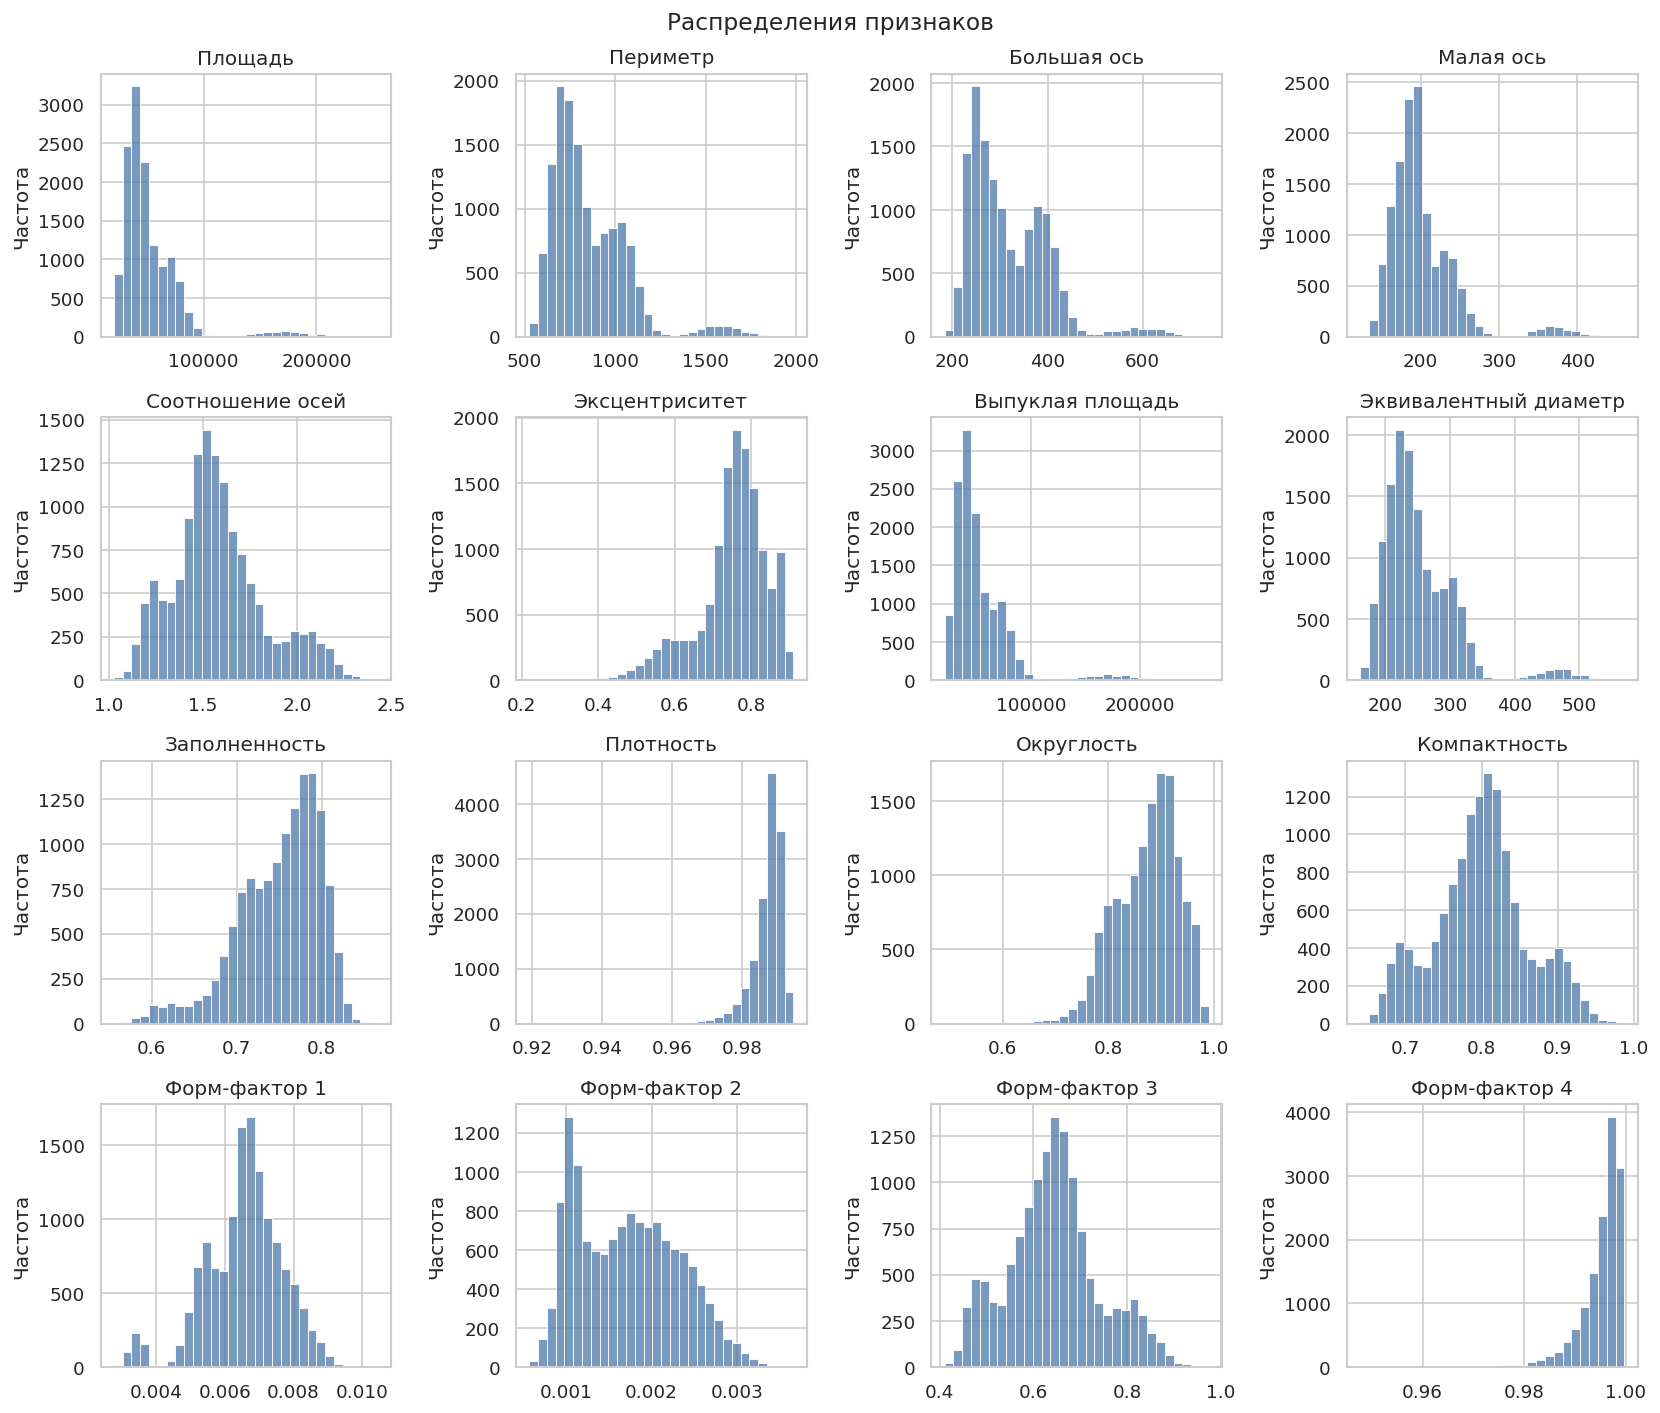

,асимметрия,p-value Шапиро
Признак,,
Площадь,2.953,0.0
Периметр,1.626,0.0
Большая ось,1.358,0.0
Малая ось,2.238,0.0
Соотношение осей,0.583,0.0
Эксцентриситет,-1.063,0.0
Выпуклая площадь,2.942,0.0
Эквивалентный диаметр,1.949,0.0
Заполненность,-0.895,0.0


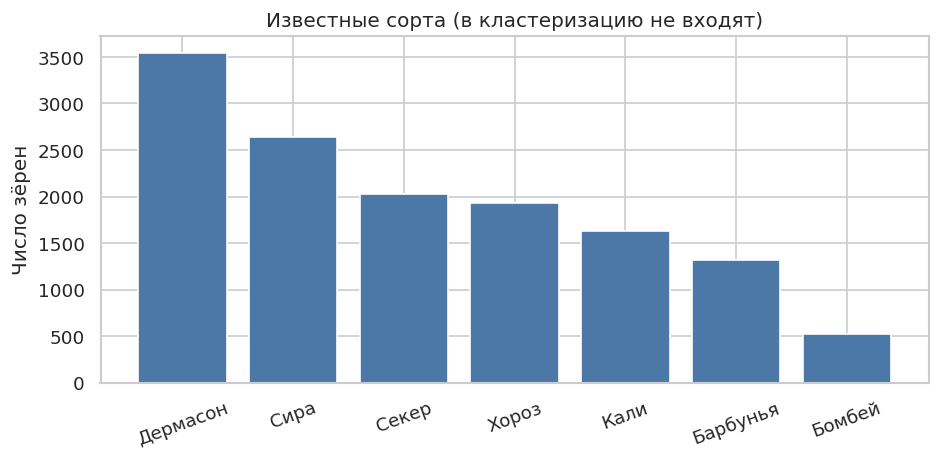

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.histplot(raw[column], bins=30, ax=ax, color="#4C78A8")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
    ax.set_ylabel("Частота")
fig.suptitle("Распределения признаков", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_histograms.png", bbox_inches="tight")
plt.show()

normality_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for column in FEATURES:
    sample = raw[column].to_numpy()
    if len(sample) > 500:
        sample = rng.choice(sample, size=500, replace=False)
    stat, pvalue = shapiro(sample)
    normality_rows.append({
        "Признак": LABELS[column],
        "асимметрия": float(raw[column].skew()),
        "p-value Шапиро": float(pvalue),
    })
normality = pd.DataFrame(normality_rows).set_index("Признак")
normality.to_csv(OUTPUT_DIR / "normality.csv", encoding="utf-8-sig")
display(normality.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts.index, class_counts.values, color="#4C78A8")
ax.set_ylabel("Число зёрен")
ax.set_title("Известные сорта (в кластеризацию не входят)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_varieties.png", bbox_inches="tight")
plt.show()


### Пояснение к выбросам и условиям кластеризации

На ящиках с усами прямоугольник — это середина выборки, от 25% до 75%. Усы доходят до полутора межквартильных размахов. Точки за усами программа считает необычными. Больше всего таких точек у эксцентриситета (843), плотности (778) и форм-фактора 4 (767). Хотя бы один необычный признак есть у 3017 строк из 13611, то есть примерно у каждой пятой.

Среди этих 3017 строк доля Бомбея только 0,17. Крайние значения есть и у Хороза, Секера и Кали. Это не сбои измерения: крупный и вытянутый сорт так и должен вылезать за усы коробки, построенной по всем зёрнам сразу. Если удалить хвост, вместе с ним пропадёт почти весь Бомбей, и отдельная группа крупных зёрен исчезнет. Поэтому все 13611 строк остаются.

Кластеризовать данные есть смысл. Сорт в признаки не подаётся, готовых ярлыков алгоритм не видит. При этом группы ожидаемы: зёрна отличаются размером и вытянутостью, и это видно уже на гистограммах и ящиках. Задача методов — найти эти группы самим.


,выбросы по IQR
Признак,
Площадь,551
Периметр,500
Большая ось,379
Малая ось,569
Соотношение осей,473
Эксцентриситет,843
Выпуклая площадь,550
Эквивалентный диаметр,526
Заполненность,275


Строк хотя бы с одним выбросом: 3017
Доля сорта Бомбей среди таких строк: 0.173


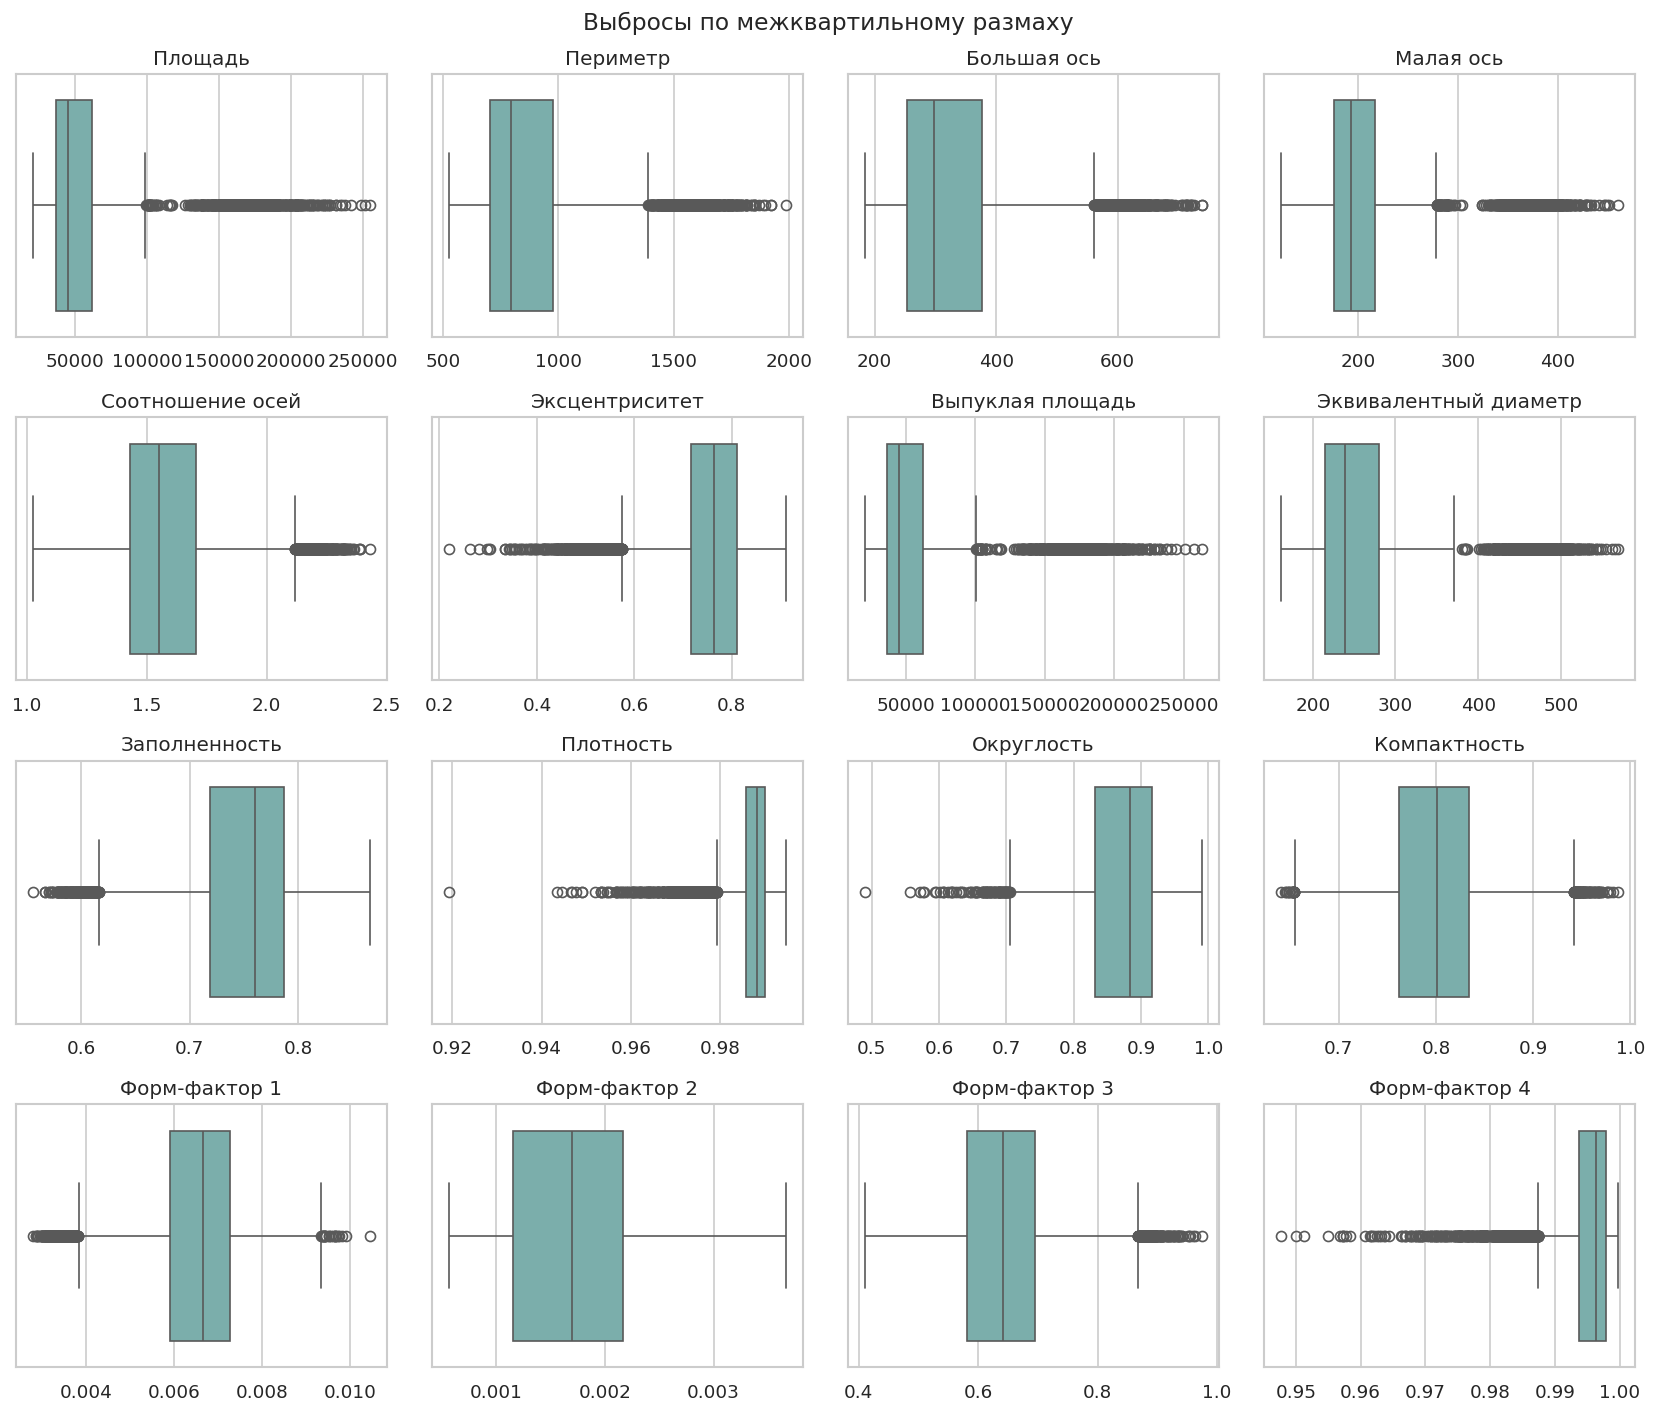

In [4]:
outlier_rows = []
outlier_mask = pd.Series(False, index=raw.index)
for column in FEATURES:
    q1 = raw[column].quantile(0.25)
    q3 = raw[column].quantile(0.75)
    iqr = q3 - q1
    mask = (raw[column] < q1 - 1.5 * iqr) | (raw[column] > q3 + 1.5 * iqr)
    outlier_mask = outlier_mask | mask
    outlier_rows.append({"Признак": LABELS[column], "выбросы по IQR": int(mask.sum())})
outlier_table = pd.DataFrame(outlier_rows).set_index("Признак")
display(outlier_table)
print(f"Строк хотя бы с одним выбросом: {int(outlier_mask.sum())}")
bombay_share = float((raw.loc[outlier_mask, TARGET] == "BOMBAY").mean()) if outlier_mask.any() else 0.0
print(f"Доля сорта Бомбей среди таких строк: {bombay_share:.3f}")

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=raw[column], ax=ax, color="#72B7B2")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
fig.suptitle("Выбросы по межквартильному размаху", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_boxplots.png", bbox_inches="tight")
plt.show()


,столбец,признак,стандартное отклонение,коэффициент вариации,взаимная информация с сортом,доля дисперсии между сортами
1,Perimeter,Периметр,214.290,0.251,1.057,0.915
6,ConvexArea,Выпуклая площадь,29774.916,0.554,1.039,0.927
7,EquivDiameter,Эквивалентный диаметр,59.177,0.234,1.037,0.918
0,Area,Площадь,29324.096,0.553,1.037,0.928
2,MajorAxisLength,Большая ось,85.694,0.268,0.996,0.905
13,ShapeFactor2,Форм-фактор 2,0.001,0.347,0.955,0.845
12,ShapeFactor1,Форм-фактор 1,0.001,0.172,0.931,0.842
3,MinorAxisLength,Малая ось,44.970,0.222,0.928,0.908
11,Compactness,Компактность,0.062,0.077,0.836,0.818
14,ShapeFactor3,Форм-фактор 3,0.099,0.154,0.836,0.814


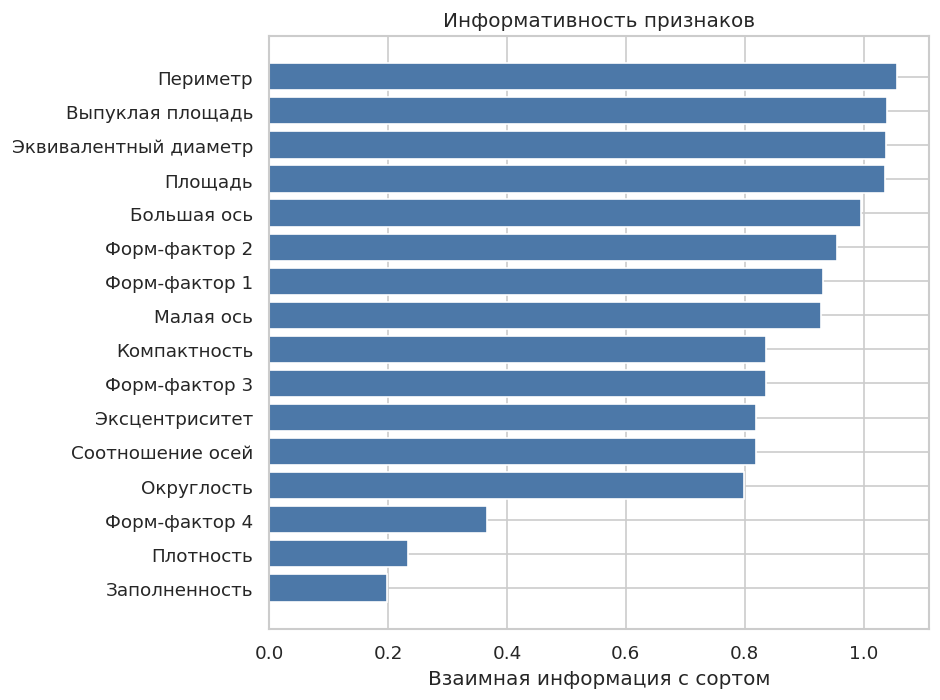

,PC1,PC2
Площадь,0.282,0.246
Периметр,0.311,0.179
Большая ось,0.326,0.101
Малая ось,0.236,0.343
Соотношение осей,0.229,-0.331
Эксцентриситет,0.232,-0.319
Выпуклая площадь,0.283,0.245
Эквивалентный диаметр,0.297,0.223
Заполненность,-0.060,0.221
Плотность,-0.143,0.103


Доля дисперсии: PC1 55.5%, PC2 26.4%


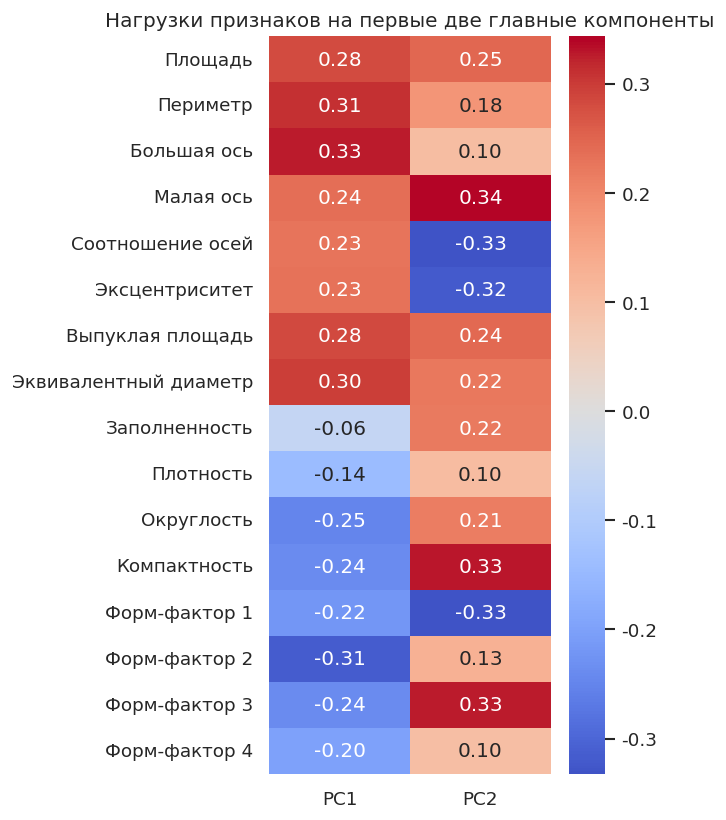

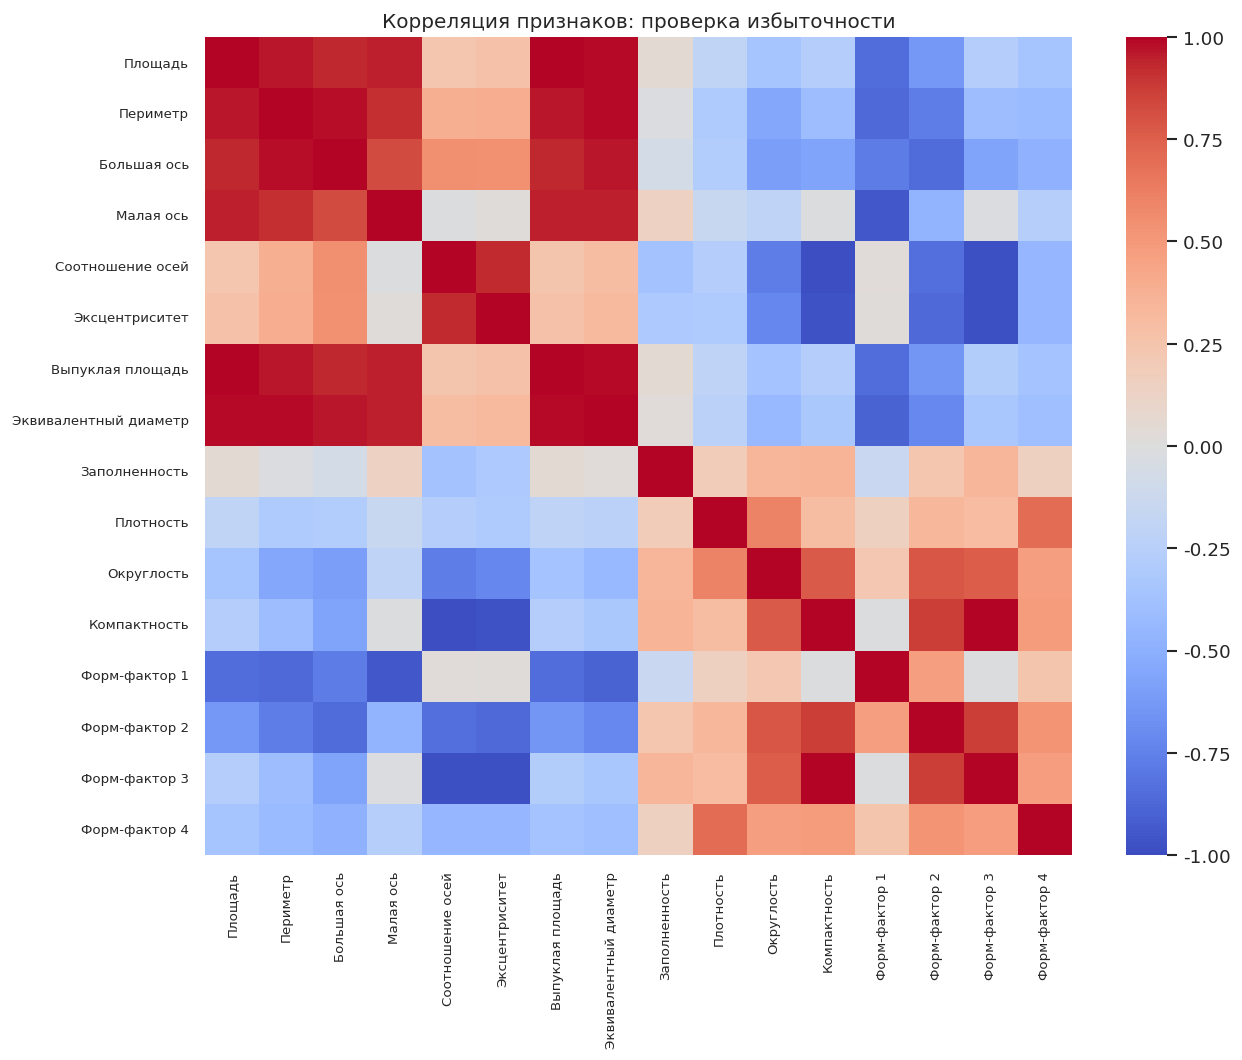

Первый разрыв в упорядоченных |r| не ниже 0,85: 0.913 и 0.893. Порог — середина разрыва, 0.903.


,|r|,признак 1,признак 2
0,1.000,Площадь,Выпуклая площадь
1,0.999,Компактность,Форм-фактор 3
2,0.991,Периметр,Эквивалентный диаметр
3,0.988,Соотношение осей,Компактность
4,0.985,Выпуклая площадь,Эквивалентный диаметр
5,0.985,Площадь,Эквивалентный диаметр
6,0.981,Эксцентриситет,Форм-фактор 3
7,0.979,Соотношение осей,Форм-фактор 3
8,0.977,Периметр,Большая ось
9,0.970,Эксцентриситет,Компактность


,удалён,взаимная информация,оставлен вместо него,|r|
0,Выпуклая площадь,1.039,Периметр,0.968
1,Эквивалентный диаметр,1.037,Периметр,0.991
2,Площадь,1.037,Периметр,0.967
3,Большая ось,0.996,Периметр,0.977
4,Малая ось,0.928,Форм-фактор 1,0.947
5,Форм-фактор 3,0.836,Компактность,0.999
6,Эксцентриситет,0.820,Компактность,0.970
7,Соотношение осей,0.820,Компактность,0.988


Оставлены:
- Периметр
- Заполненность
- Плотность
- Округлость
- Компактность
- Форм-фактор 1
- Форм-фактор 2
- Форм-фактор 4
Осталось признаков: 8


In [5]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    groups = np.asarray(groups)
    overall = values.mean()
    ss_total = float(np.sum((values - overall) ** 2))
    ss_between = 0.0
    for group in np.unique(groups):
        part = values[groups == group]
        ss_between += len(part) * (part.mean() - overall) ** 2
    return float(ss_between / ss_total)


mi_values = mutual_info_classif(
    raw[FEATURES], raw[TARGET], discrete_features=False, random_state=RANDOM_STATE
)
info = pd.DataFrame({
    "столбец": FEATURES,
    "признак": [LABELS[column] for column in FEATURES],
    "стандартное отклонение": [float(raw[column].std()) for column in FEATURES],
    "коэффициент вариации": [float(raw[column].std() / raw[column].mean()) for column in FEATURES],
    "взаимная информация с сортом": mi_values,
    "доля дисперсии между сортами": [eta_squared(raw[column], raw[TARGET]) for column in FEATURES],
})
info = info.sort_values("взаимная информация с сортом", ascending=False)
info.to_csv(OUTPUT_DIR / "feature_information.csv", index=False, encoding="utf-8-sig")
display(info.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
ordered = info.sort_values("взаимная информация с сортом", ascending=True)
ax.barh(ordered["признак"], ordered["взаимная информация с сортом"], color="#4C78A8")
ax.set_xlabel("Взаимная информация с сортом")
ax.set_title("Информативность признаков")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04b_mutual_info.png", bbox_inches="tight")
plt.show()

full_scaled = StandardScaler().fit_transform(raw[FEATURES])
pca_full = PCA(n_components=2, random_state=RANDOM_STATE)
pca_full.fit(full_scaled)
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=[LABELS[column] for column in FEATURES],
    columns=["PC1", "PC2"],
)
loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv", encoding="utf-8-sig")
display(loadings.round(3))
print(
    f"Доля дисперсии: PC1 {pca_full.explained_variance_ratio_[0]:.1%}, "
    f"PC2 {pca_full.explained_variance_ratio_[1]:.1%}"
)

fig, ax = plt.subplots(figsize=(5.5, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Нагрузки признаков на первые две главные компоненты")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04c_pca_loadings.png", bbox_inches="tight")
plt.show()

corr = raw[FEATURES].corr()
corr.rename(index=LABELS, columns=LABELS).to_csv(OUTPUT_DIR / "correlation.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr.rename(index=LABELS, columns=LABELS),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    xticklabels=True,
    yticklabels=True,
)
ax.tick_params(axis="both", labelsize=8)
ax.set_title("Корреляция признаков: проверка избыточности")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_correlation.png", bbox_inches="tight")
plt.show()

abs_corr = corr.abs()
pairs = []
for i, left in enumerate(FEATURES):
    for right in FEATURES[i + 1:]:
        pairs.append((float(abs_corr.loc[left, right]), left, right))
pairs.sort(reverse=True)
pair_values = [item[0] for item in pairs]
gap_index = next(
    index
    for index in range(len(pair_values) - 1)
    if pair_values[index] >= 0.85 and pair_values[index] - pair_values[index + 1] >= 0.02
)
high_link, low_link = pair_values[gap_index], pair_values[gap_index + 1]
redundancy_threshold = (high_link + low_link) / 2
print(
    f"Первый разрыв в упорядоченных |r| не ниже 0,85: "
    f"{high_link:.3f} и {low_link:.3f}. Порог — середина разрыва, {redundancy_threshold:.3f}."
)
strong_pairs = pd.DataFrame(
    [
        {"|r|": value, "признак 1": LABELS[left], "признак 2": LABELS[right]}
        for value, left, right in pairs
        if value >= redundancy_threshold
    ]
)
display(strong_pairs.round(3))

kept = []
dropped_rows = []
for index in np.argsort(mi_values)[::-1]:
    name = FEATURES[index]
    if not kept:
        kept.append(name)
        continue
    rival = max(kept, key=lambda other: float(abs_corr.loc[name, other]))
    link = float(abs_corr.loc[name, rival])
    if link >= redundancy_threshold:
        dropped_rows.append({
            "удалён": LABELS[name],
            "взаимная информация": float(mi_values[index]),
            "оставлен вместо него": LABELS[rival],
            "|r|": link,
        })
    else:
        kept.append(name)
kept = [column for column in FEATURES if column in kept]
dropped_table = pd.DataFrame(dropped_rows)
dropped_table.to_csv(OUTPUT_DIR / "dropped_features.csv", index=False, encoding="utf-8-sig")
display(dropped_table.round(3))
print("Оставлены:")
for column in kept:
    print(f"- {LABELS[column]}")
print(f"Осталось признаков: {len(kept)}")


### Пояснение к информативности и избыточности

Информативность и избыточность здесь считаются отдельно. Информативность отвечает, различает ли столбец зёрна. Избыточность отвечает, не записан ли тот же факт вторым столбцом.

Столбчатая диаграмма и таблица `feature_information.csv` сортируют 16 измерений по взаимной информации с сортом. Сорт в кластеризацию не подаётся: эта величина только измеряет, насколько признак связан с известными сортами. Выше всех периметр, 1,057. Рядом выпуклая площадь 1,039, эквивалентный диаметр и площадь по 1,037, большая ось 0,996. Это блок размера. Форм-фактор 2 даёт 0,955, форм-фактор 1 — 0,931. Ниже всех заполненность 0,199, плотность 0,234 и форм-фактор 4 — 0,367.

Доля дисперсии между сортами читается так же. У площади она 0,928: сорта объясняют почти весь разброс площади. У заполненности 0,157. Коэффициент вариации нужен потому, что сырое стандартное отклонение площади равно 29324, а у периметра 214: это разные единицы, и по ним информативность не сравнивают. У форм-фактора 4 и плотности коэффициент вариации около 0,004, столбец почти постоянный, поэтому и взаимная информация низкая. У площади коэффициент 0,553, разброс относительно своего среднего большой.

Нагрузки PCA посчитаны по всем 16 столбцам после отдельной стандартизации, до отбрасывания копий. Первая компонента забирает 55,5% дисперсии, вторая 26,4%. На первую сильнее всего выходят большая ось (0,33), периметр (0,31) и форм-фактор 2 (−0,32): это направление размера. На вторую — малая ось (0,34), соотношение осей (−0,33), компактность и форм-фактор 3 (около 0,33): это направление формы.

Тепловая карта ниже — проверка копий, а не информативности. Все пары упорядочены по модулю корреляции Пирсона. Первый разрыв не меньше 0,02 среди связей от 0,85 и выше лежит между 0,913 и 0,893. Порог поставлен в середину этого разрыва и равен 0,903. Его печатает ячейка вместе со списком пар выше порога. Самые тесные пары — площадь и выпуклая площадь, 1,000, компактность и форм-фактор 3, 0,999, периметр и эквивалентный диаметр, 0,991.

Дальше столбцы идут от большей взаимной информации к меньшей. Очередной столбец остаётся, если его связь с каждым уже оставленным ниже 0,903. Иначе остаётся тот, у кого взаимная информация выше. Поэтому из блока размера остаётся периметр: выпуклая площадь, эквивалентный диаметр, площадь и большая ось связаны с ним на 0,967–0,991 и чуть менее информативны. Малая ось снята из-за форм-фактора 1, |r| = 0,947. Форм-фактор 3, эксцентриситет и соотношение осей сняты из-за компактности, |r| равен 0,999, 0,970 и 0,988.

В матрице признаков остаются 8 столбцов: периметр, заполненность, плотность, округлость, компактность и форм-факторы 1, 2 и 4. Заполненность и плотность слабо связаны с сортом, но ни один оставленный столбец их не копирует, поэтому правило избыточности их сохраняет.


,mean,std
Периметр,-0.0,1.0
Заполненность,0.0,1.0
Плотность,0.0,1.0
Округлость,0.0,1.0
Компактность,-0.0,1.0
Форм-фактор 1,0.0,1.0
Форм-фактор 2,-0.0,1.0
Форм-фактор 4,0.0,1.0


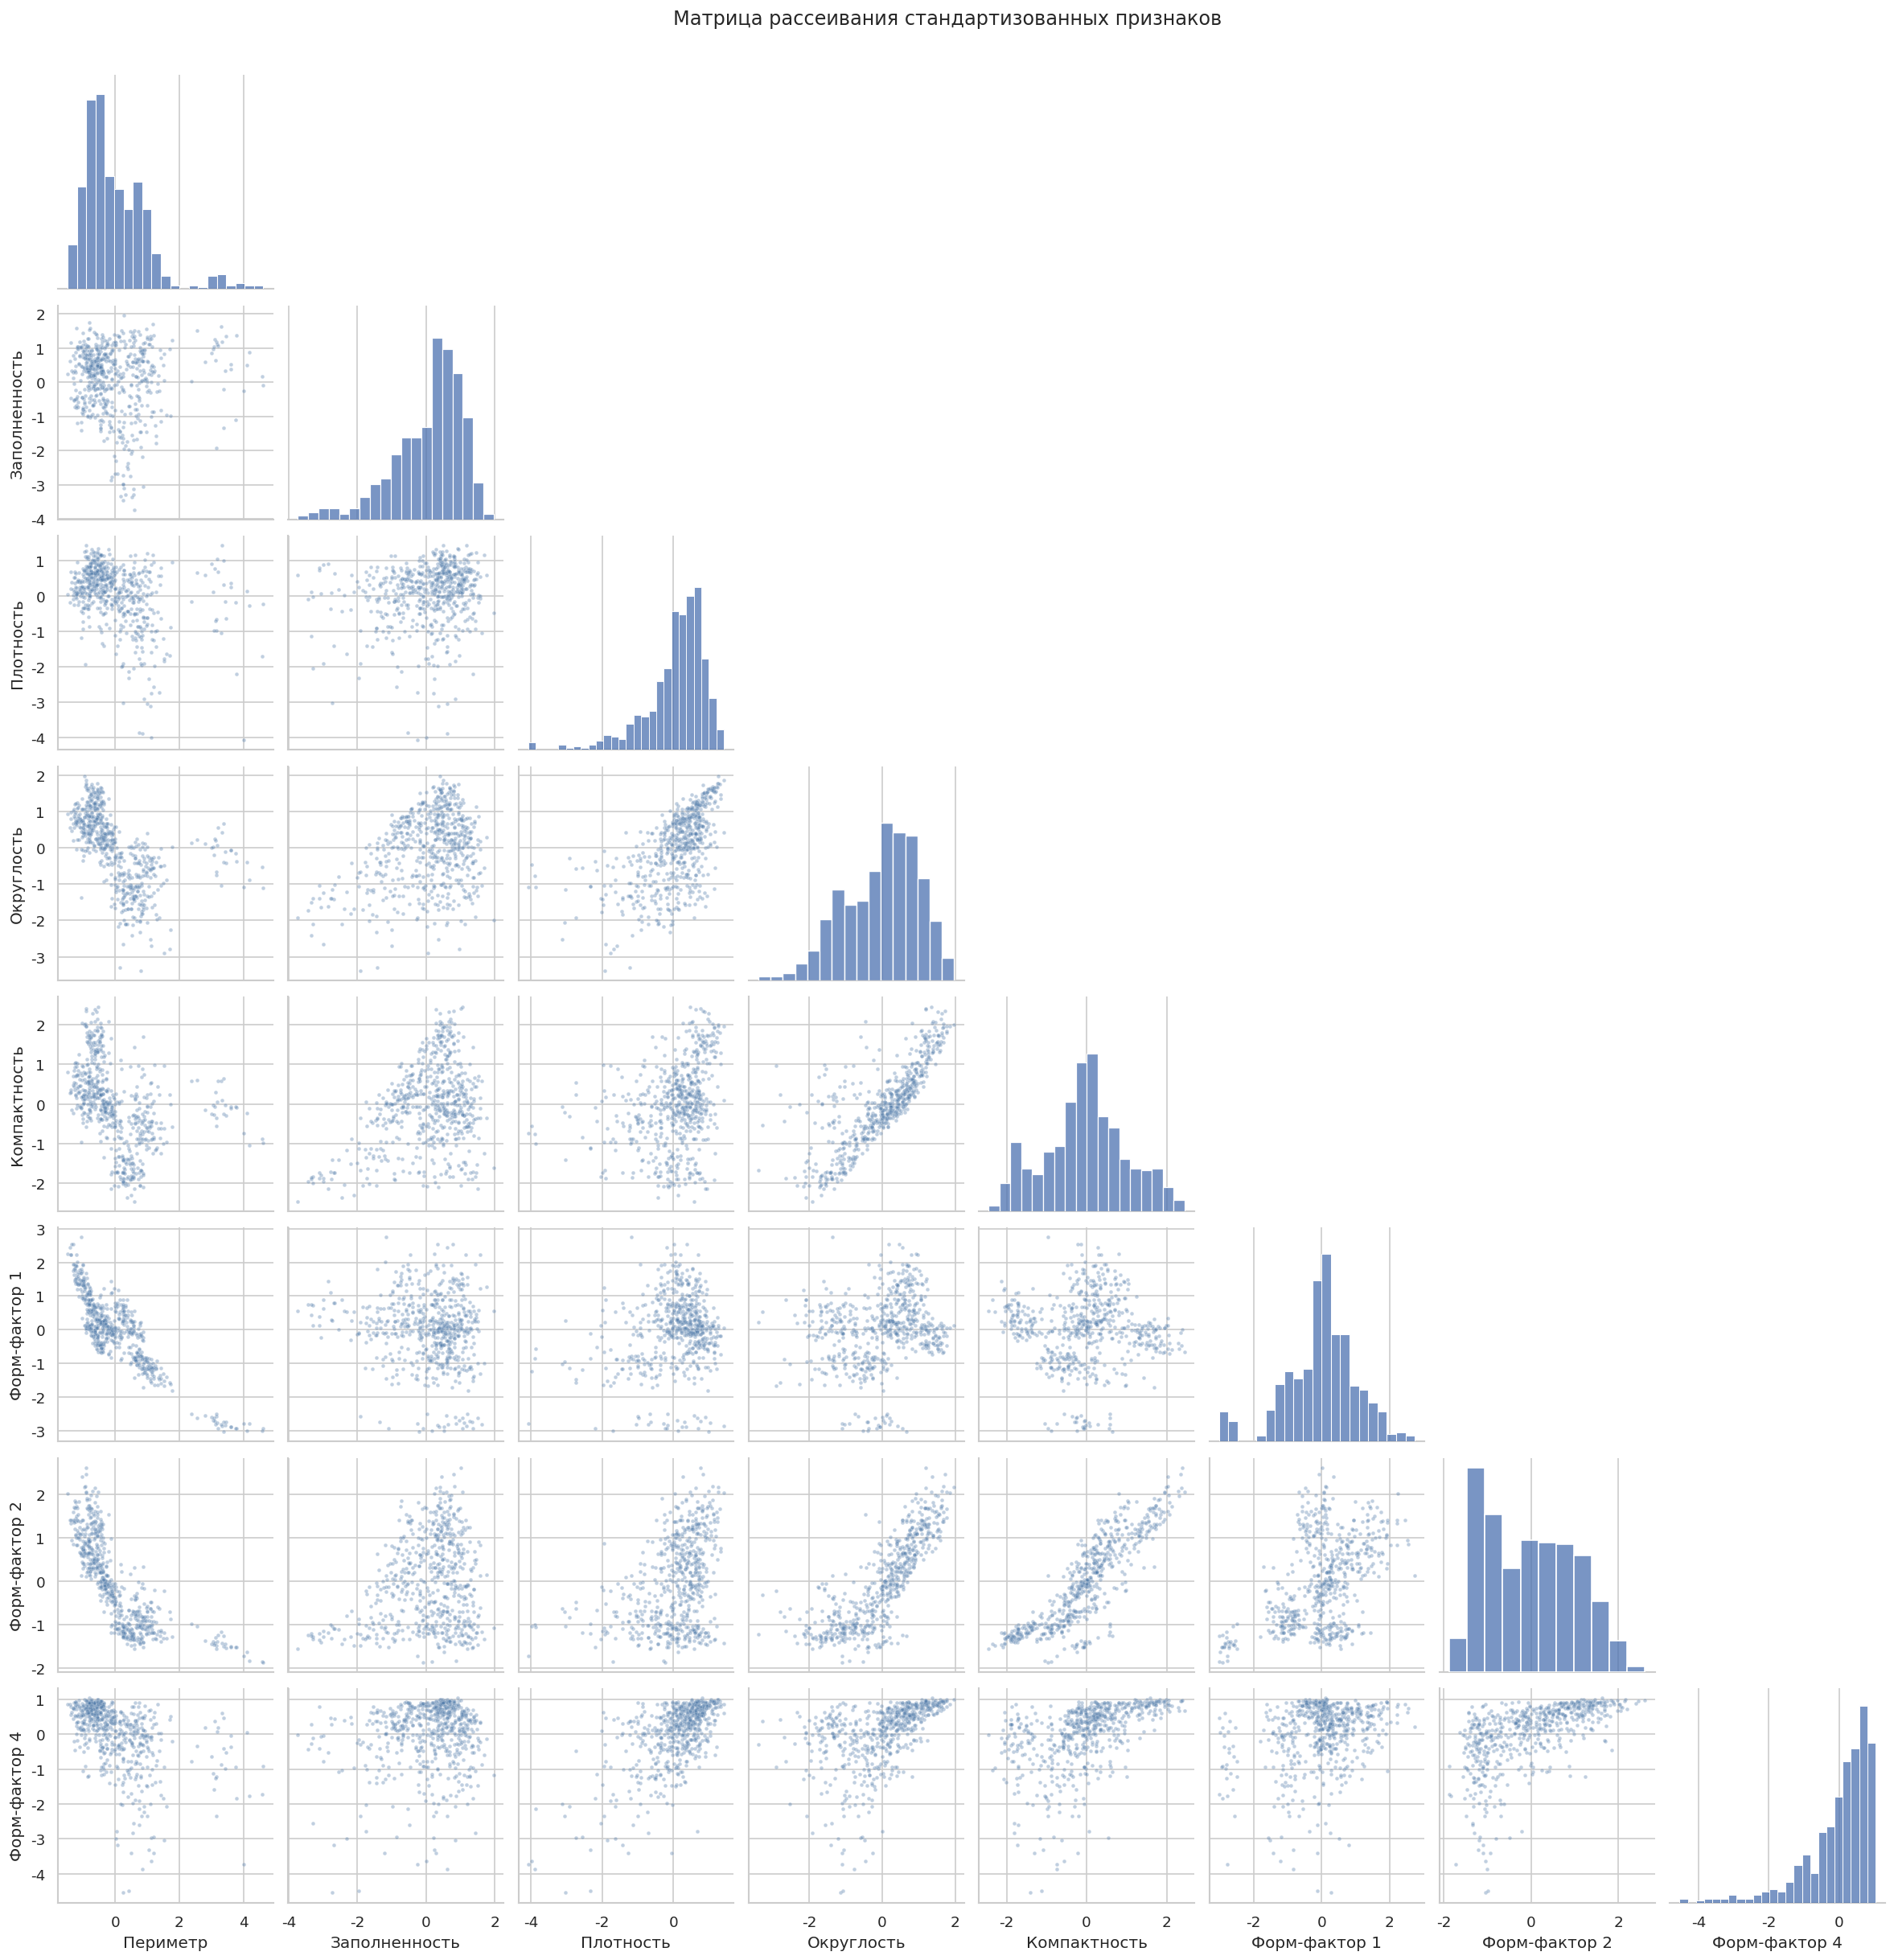

In [6]:
x = raw[kept].copy()
y = raw[TARGET].copy()
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
scaled_frame = pd.DataFrame(x_scaled, columns=kept)
display(scaled_frame.describe().T[["mean", "std"]].rename(index=LABELS).round(3))

plot_frame = scaled_frame.copy()
plot_frame.columns = [LABELS[column] for column in kept]
sample = plot_frame.sample(n=600, random_state=RANDOM_STATE)
grid = sns.pairplot(sample, corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": "#4C78A8"}, diag_kind="hist")
grid.figure.suptitle("Матрица рассеивания стандартизованных признаков", y=1.02)
grid.figure.savefig(OUTPUT_DIR / "05_pairplot.png", bbox_inches="tight")
plt.show()


### Пояснение к масштабированию и матрице рассеивания

После стандартизации у каждого из 8 оставшихся признаков среднее 0 и разброс 1. До этого периметр измерялся сотнями пикселей, а округлость и компактность лежали около единицы. Без выравнивания расстояние между зёрнами почти целиком определял бы периметр.

StandardScaler вычитает среднее и делит на стандартное отклонение. MinMax сжал бы всё в отрезок от 0 до 1 и оставил бы одному самому крупному зерну право задавать край шкалы. RobustScaler приглушил бы хвосты медианой. Здесь хвост — это настоящий крупный сорт, его приглушать не нужно. Скалер обучен на всех 13611 строках: отдельной тестовой выборки нет, группы ищутся на той же таблице, которую потом описывают. Сорт в скалер не входит.

Матрица рассеяния построена по 600 случайным зёрнам, иначе 13611 точек слиплись бы в пятно. По диагонали — гистограммы уже в стандартной шкале. Вне диагонали облака вытянуты и накладываются: часть зёрен компактна, часть вытянута, круглых отделённых пятен нет. Поэтому рядом с K-means, который собирает группы вокруг центров, взят Gaussian Mixture. Он умеет эллипсы и разную ковариацию.


Для силуэта зафиксированы 3000 индексов. Один и тот же набор передаётся во все сравнения.


,k,инерция,силуэт,относительное падение к следующему k
0,2,66859.232,0.374,0.143
1,3,57277.217,0.357,0.137
2,4,49445.934,0.335,0.146
3,5,42246.703,0.277,0.118
4,6,37264.376,0.290,0.086
5,7,34067.882,0.292,0.091
6,8,30981.033,0.282,0.068
7,9,28876.740,0.279,0.071
8,10,26814.249,0.286,NaN


Локоть, где падение инерции впервые меньше 0,10: k=6
Максимум силуэта: k=2, значение 0.374
В модель берётся максимум силуэта: k=2


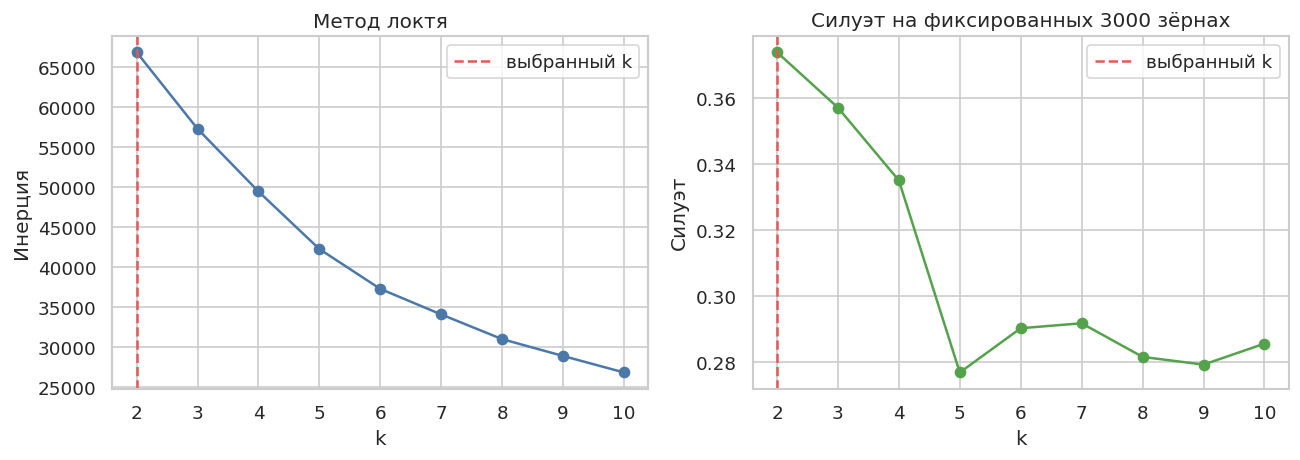

In [7]:
rng_silhouette = np.random.default_rng(RANDOM_STATE)
SILHOUETTE_INDEX = np.sort(rng_silhouette.choice(len(x_scaled), size=3000, replace=False))
pd.Series(SILHOUETTE_INDEX, name="index").to_csv(
    OUTPUT_DIR / "silhouette_index.csv", index=False, encoding="utf-8-sig"
)
print(f"Для силуэта зафиксированы {len(SILHOUETTE_INDEX)} индексов. Один и тот же набор передаётся во все сравнения.")


def fixed_silhouette(points, labels):
    points = np.asarray(points)
    labels = np.asarray(labels)
    return float(silhouette_score(points[SILHOUETTE_INDEX], labels[SILHOUETTE_INDEX]))


ks = list(range(2, 11))
inertias = []
silhouettes = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(x_scaled)
    inertias.append(float(model.inertia_))
    silhouettes.append(fixed_silhouette(x_scaled, labels))

drops = [(inertias[i] - inertias[i + 1]) / inertias[i] for i in range(len(inertias) - 1)]
elbow_k = ks[-1]
for k, drop in zip(ks[:-1], drops):
    if drop < 0.10:
        elbow_k = k
        break
silhouette_k = ks[int(np.argmax(silhouettes))]
best_k = silhouette_k

k_table = pd.DataFrame({
    "k": ks,
    "инерция": inertias,
    "силуэт": silhouettes,
    "относительное падение к следующему k": drops + [np.nan],
})
k_table.to_csv(OUTPUT_DIR / "k_selection.csv", index=False, encoding="utf-8-sig")
display(k_table.round(3))
print(f"Локоть, где падение инерции впервые меньше 0,10: k={elbow_k}")
print(f"Максимум силуэта: k={silhouette_k}, значение {max(silhouettes):.3f}")
print(f"В модель берётся максимум силуэта: k={best_k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o", color="#4C78A8")
axes[0].axvline(best_k, color="#E45756", linestyle="--", label="выбранный k")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[0].set_title("Метод локтя")
axes[0].legend()
axes[1].plot(ks, silhouettes, marker="o", color="#54A24B")
axes[1].axvline(best_k, color="#E45756", linestyle="--", label="выбранный k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Силуэт")
axes[1].set_title("Силуэт на фиксированных 3000 зёрнах")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_k_selection.png", bbox_inches="tight")
plt.show()


### Пояснение к выбору числа кластеров

Левый график — инерция, сумма квадратов расстояний до своего центра. Она падает при каждом новом центре, поэтому смотреть нужно на замедление, а не на сам минимум. Правый график — средний силуэт. Он близок к 1, когда зерно плотно лежит среди своих и далеко от чужих, и близок к 0 на широкой границе.

Силуэт для всех k и для всех моделей дальше считается на одних и тех же 3000 зёрнах. Индексы выбраны один раз генератором с `random_state = 42`, записаны в `output/silhouette_index.csv` и передаются в расчёт срезом этих строк. Новый случайный набор внутри `silhouette_score` не вызывается.

Числа на этих индексах:

- k = 2: инерция 66859, силуэт 0,374. Это максимум силуэта. Относительное падение инерции к k = 3 равно 0,143.
- k = 3: инерция 57277, силуэт 0,357. Падение к следующему k равно 0,137.
- k = 4: инерция 49446, силуэт 0,335. Падение 0,146.
- k = 5: инерция 42247, силуэт 0,277. Падение 0,118, силуэт просел.
- k = 6: инерция 37264, силуэт 0,290. Падение к k = 7 равно 0,086.
- k = 7: инерция 34068, силуэт 0,292.
- k = 8, 9 и 10: инерция ползёт вниз, силуэт остаётся около 0,28.

Локоть по правилу «первое k, после которого относительное падение меньше 0,10» приходится на k = 6. Силуэт там 0,290. В модель берётся максимум силуэта, k = 2. Локоть нарисован в таблице и на левом графике как описание инерции. Отдельного правила «если силуэты различаются меньше чем на 0,05, взять локоть» нет: оно как раз сдвигало бы ответ от максимума силуэта к более дробному k. Семь сортов в формулу не входят. Вертикальная линия стоит на двойке. Ниже по центрам видно, что это разрез «более мелкие и округлые» против «более крупных и вытянутых».


In [8]:
def jaccard_index(y_true, y_pred):
    matrix = pair_confusion_matrix(y_true, y_pred)
    true_negative, false_positive, false_negative, true_positive = matrix.ravel()
    denominator = true_positive + false_positive + false_negative
    if denominator == 0:
        return 0.0
    return float(true_positive / denominator)


def clustering_metrics(name, labels, centers, points, space):
    points = np.asarray(points)
    labels = np.asarray(labels)
    centers = np.asarray(centers)
    intra = []
    for index, center in enumerate(centers):
        members = points[labels == index]
        if len(members) == 0:
            continue
        intra.append(float(np.mean(np.linalg.norm(members - center, axis=1))))
    distances = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    upper = distances[np.triu_indices(len(centers), k=1)]
    return {
        "Модель": name,
        "пространство": space,
        "Силуэт": fixed_silhouette(points, labels),
        "Calinski-Harabasz": float(calinski_harabasz_score(points, labels)),
        "Davies-Bouldin": float(davies_bouldin_score(points, labels)),
        "Среднее внутри кластера": float(np.mean(intra)) if intra else np.nan,
        "Среднее между центрами": float(np.mean(upper)),
        "Минимум между центрами": float(np.min(upper)),
        "Rand": float(rand_score(y, labels)),
        "ARI": float(adjusted_rand_score(y, labels)),
        "NMI": float(normalized_mutual_info_score(y, labels)),
        "Жаккар": jaccard_index(y, labels),
    }


kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(x_scaled)
kmeans_centers = kmeans.cluster_centers_

covariance_rows = []
gmm_models = {}
for covariance in ("spherical", "diag", "tied", "full"):
    model = GaussianMixture(
        n_components=best_k,
        covariance_type=covariance,
        n_init=2,
        reg_covar=1e-4,
        random_state=RANDOM_STATE,
    )
    labels = model.fit_predict(x_scaled)
    score = fixed_silhouette(x_scaled, labels)
    covariance_rows.append({"ковариация": covariance, "силуэт": score, "BIC": float(model.bic(x_scaled))})
    gmm_models[covariance] = (model, labels)

covariance_table = pd.DataFrame(covariance_rows).set_index("ковариация")
best_covariance = covariance_table["силуэт"].idxmax()
gmm, gmm_labels = gmm_models[best_covariance]
gmm_centers = gmm.means_

metric_rows = [
    clustering_metrics("K-means", kmeans_labels, kmeans_centers, x_scaled, "исходные признаки"),
    clustering_metrics("GMM", gmm_labels, gmm_centers, x_scaled, "исходные признаки"),
]
metrics = pd.DataFrame(metric_rows).set_index("Модель")
metrics.to_csv(OUTPUT_DIR / "metrics_classical.csv", encoding="utf-8-sig")
covariance_table.to_csv(OUTPUT_DIR / "gmm_covariance.csv", encoding="utf-8-sig")
display(metrics.round(3))
display(covariance_table.round(3))


def centers_in_original(centers):
    frame = pd.DataFrame(scaler.inverse_transform(centers), columns=kept)
    frame.columns = [LABELS[column] for column in kept]
    return frame


kmeans_original = centers_in_original(kmeans_centers)
kmeans_original.index = [f"кластер {i}" for i in range(best_k)]
kmeans_original.to_csv(OUTPUT_DIR / "kmeans_centers.csv", encoding="utf-8-sig")
display(kmeans_original.round(2))

crosstab = pd.crosstab(
    pd.Series(kmeans_labels, name="кластер K-means"),
    y.map(VARIETY),
)
crosstab.to_csv(OUTPUT_DIR / "kmeans_crosstab.csv", encoding="utf-8-sig")
display(crosstab)

cluster_spread = pd.DataFrame({
    "признак": [LABELS[column] for column in kept],
    "доля дисперсии между кластерами K-means": [eta_squared(raw[column], kmeans_labels) for column in kept],
    "доля дисперсии между сортами": [eta_squared(raw[column], y) for column in kept],
}).sort_values("доля дисперсии между кластерами K-means", ascending=False)
cluster_spread.to_csv(OUTPUT_DIR / "cluster_spread.csv", index=False, encoding="utf-8-sig")
display(cluster_spread.round(3))


,пространство,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,,
K-means,исходные признаки,0.374,8554.833,1.156,2.051,3.547,3.547,0.631,0.272,0.416,0.298
GMM,исходные признаки,0.373,7961.303,1.196,2.119,3.516,3.516,0.624,0.275,0.414,0.302


,силуэт,BIC
ковариация,,
spherical,0.363,259391.095
diag,0.364,242874.253
tied,0.373,171799.554
full,0.372,100634.438


,Периметр,Заполненность,Плотность,Округлость,Компактность,Форм-фактор 1,Форм-фактор 2,Форм-фактор 4
кластер 0,716.55,0.76,0.99,0.91,0.84,0.01,0.0,1.00
кластер 1,1037.58,0.74,0.98,0.82,0.75,0.01,0.0,0.99


Class,Барбунья,Бомбей,Дермасон,Кали,Секер,Сира,Хороз
кластер K-means,,,,,,,
0,72,0,3497,19,2013,2102,25
1,1250,522,49,1611,14,534,1903


,признак,доля дисперсии между кластерами K-means,доля дисперсии между сортами
6,Форм-фактор 2,0.666,0.845
3,Округлость,0.611,0.731
0,Периметр,0.551,0.915
4,Компактность,0.439,0.818
7,Форм-фактор 4,0.286,0.356
5,Форм-фактор 1,0.275,0.842
2,Плотность,0.209,0.218
1,Заполненность,0.050,0.157


### Пояснение к K-means и GMM

K-means делит 13611 зёрен на 2 группы, число взято по максимуму силуэта. Запуск повторён 10 раз, оставлен вариант с меньшей инерцией. GMM — это EM-алгоритм: у каждой группы есть вес, центр и эллипс. Из четырёх типов ковариации по силуэту на тех же 3000 индексах выбран `tied`. Сорта в оба обучения не входили.

Внутренние метрики этой таблицы посчитаны в восьми стандартизованных признаках. Силуэт — на зафиксированных индексах, остальные внутренние метрики — по всем 13611 строкам, они подвыборку не используют. Внешние метрики сравнивают готовые метки с семью сортами и от координат не зависят.

Как читать строку:

- Силуэт: выше лучше, шкала от −1 до 1. 0,374 — группы есть, граница всё ещё широкая.
- Calinski–Harabasz: выше лучше, отношение разброса между центрами к разбросу внутри.
- Davies–Bouldin: ниже лучше.
- Среднее внутри кластера — типичное расстояние зерна до своего центра. Между двумя центрами расстояние одно, поэтому среднее и минимум совпадают.
- Rand — доля пар, где алгоритм и сорт согласны «вместе» или «врозь». При семи сортах и двух кластерах много пар из разных сортов попадает в один кластер, поэтому Rand здесь скромнее, чем при дробном разбиении.
- ARI вычитает случайное согласие. 0 — уровень случайных меток, 1 — полное совпадение с сортами.
- NMI — общая информация двух разбиений.
- Жаккар считает пары, которые положили вместе.

**K-means.** Силуэт 0,374. Calinski–Harabasz 8555. Davies–Bouldin 1,156. Среднее расстояние до центра 2,05, расстояние между центрами 3,55: центры разъехались дальше типичного радиуса группы. Rand 0,631, ARI 0,272, NMI 0,416, Жаккар 0,298. ARI 0,272 при двух кластерах и семи сортах означает грубое, не случайное совпадение: одна группа собирает несколько сортов сразу.

**GMM, tied.** Силуэт 0,373, Calinski–Harabasz 7961, Davies–Bouldin 1,196. Расстояния 2,12 до центра и 3,52 между центрами. Rand 0,624, ARI 0,275, NMI 0,414, Жаккар 0,302. По силуэту и Calinski–Harabasz чуть впереди K-means, по ARI и Жаккару чуть впереди GMM. Разрыв в третьем знаке: оба метода видят одну и ту же пару облаков.

Таблица под центрами показывает, какая доля дисперсии каждого оставленного признака приходится на различие этих двух кластеров. Сильнее всего кластеры расходятся по форм-фактору 2 (0,666), округлости (0,611) и периметру (0,551). Заполненность даёт только 0,050: столбец в наборе есть, потому что он не копия другого, а найденные группы его почти не используют.


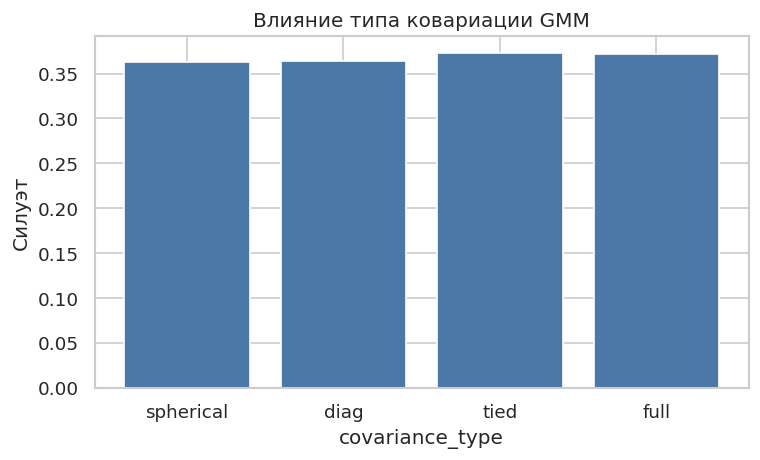

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(covariance_table.index, covariance_table["силуэт"], color="#4C78A8")
ax.set_ylabel("Силуэт")
ax.set_xlabel("covariance_type")
ax.set_title("Влияние типа ковариации GMM")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_gmm_covariance.png", bbox_inches="tight")
plt.show()


### Пояснение к влиянию параметров

Число кластеров разобрано на графике силуэта: максимум при k = 2 равен 0,374, при k = 6 силуэт 0,290. В оба метода поставлено k = 2.

Столбчатая диаграмма сравнивает тип ковариации GMM при этом k. Высота столбца — силуэт на тех же 3000 индексах.

- `tied`: 0,373. Один общий эллипс на обе группы. Самый высокий столбец, его и берём.
- `full`: 0,372. Свой эллипс у каждой группы. Почти та же высота.
- `diag`: 0,364. Разный масштаб по осям, без наклона эллипса.
- `spherical`: 0,363. Каждая компонента — шар.

Разница лучшего и худшего столбца — 0,010. Смена k с 2 на 6 двигает силуэт на 0,084, то есть сильнее, чем тип эллипса. В таблице рядом есть BIC: чем он меньше, тем лучше модель с учётом числа параметров. Самый маленький BIC у `full`, 100634, против 171800 у `tied`. В расчёт взят силуэт, тем же правилом, что и сравнение с K-means. `reg_covar = 1e-4` не даёт эллипсу схлопнуться.


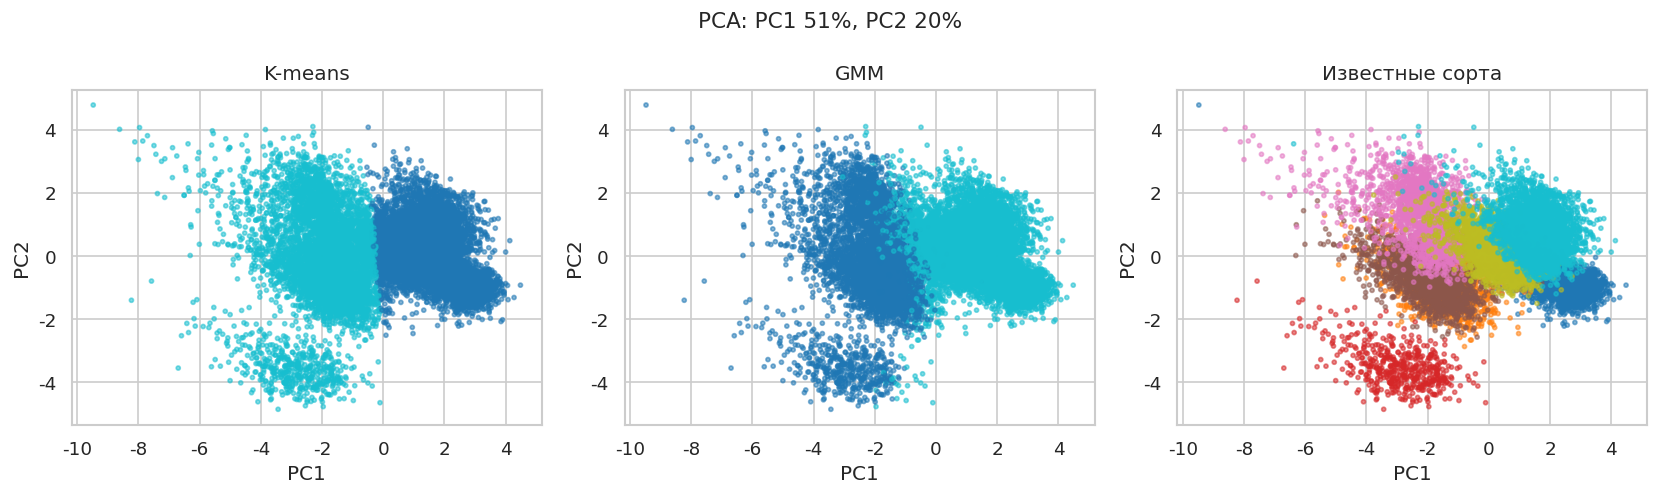

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy = pca.fit_transform(x_scaled)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
panels = (
    (kmeans_labels, "K-means"),
    (gmm_labels, "GMM"),
    (pd.factorize(y)[0], "Известные сорта"),
)
for ax, (labels, title) in zip(axes, panels):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=6, alpha=0.55)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
fig.suptitle(f"PCA: PC1 {explained[0]:.0%}, PC2 {explained[1]:.0%}", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_pca_clusters.png", bbox_inches="tight")
plt.show()


### Пояснение к визуализации и центрам K-means

PCA на рисунке не заменяет признаки в K-means. Он только кладёт 8 стандартизованных измерений на плоскость. Первая ось забирает 51,3% дисперсии, вторая 20,1%, вместе около 71%. Остальной разброс на рисунке не виден.

Три панели — одни и те же координаты. Левая раскрашена метками K-means, средняя — метками GMM, правая — сортами. Номера цветов между панелями совпадать не обязаны. На левой и средней панелях видны два облака, на правой внутри каждого облака несколько сортов лежат вместе. Это и есть содержание ARI 0,27: геометрия даёт две группы, а сортов семь.

Центры переведены из стандартной шкалы обратно в исходные единицы.

- Кластер 0, 7728 зёрен. Периметр центра 717, округлость 0,91, компактность 0,84. Это более мелкие и округлые зёрна. Здесь 3497 из 3546 зёрен Дермасона, 2013 из 2027 зёрен Секера и 2102 из 2636 зёрен Сиры. Бомбея в этой группе нет.
- Кластер 1, 5883 зерна. Периметр центра 1038, округлость 0,82, компактность 0,75. Это более крупные и вытянутые зёрна. Здесь все 522 зерна Бомбея, 1903 из 1928 зёрен Хороза, 1611 из 1630 зёрен Кали и 1250 из 1322 зёрен Барбуньи. Сира в основном остаётся в первом кластере, 534 зерна попадают во второй.

Две группы читаются как размер вместе с формой. Отдельного кластера на каждый сорт силуэт не просит: при k = 6 он падает до 0,290.


,пространство,Силуэт,Calinski-Harabasz,Davies-Bouldin,Среднее внутри кластера,Среднее между центрами,Минимум между центрами,Rand,ARI,NMI,Жаккар
Модель,,,,,,,,,,,
K-means,исходные признаки,0.374,8554.833,1.156,2.051,3.547,3.547,0.631,0.272,0.416,0.298
GMM,исходные признаки,0.373,7961.303,1.196,2.119,3.516,3.516,0.624,0.275,0.414,0.302


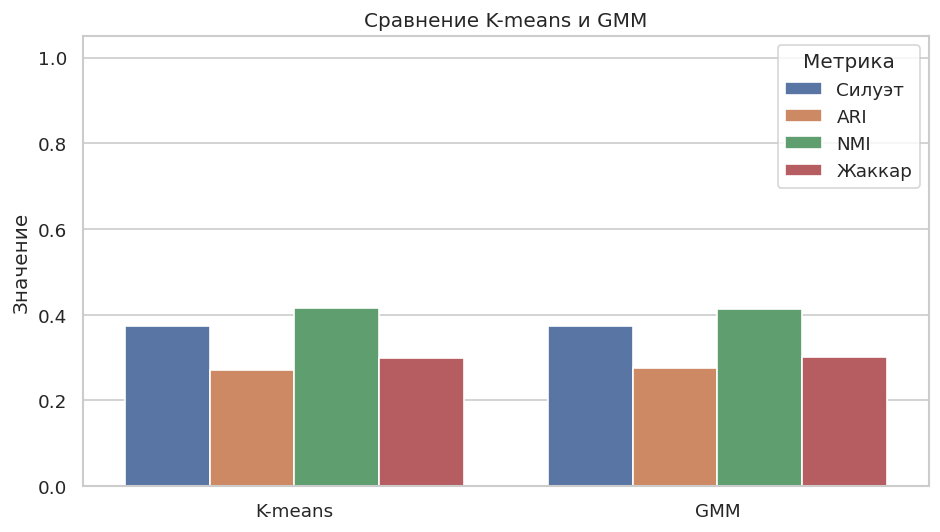

In [11]:
final_table = metrics.copy()
final_table.to_csv(OUTPUT_DIR / "metrics_all.csv", encoding="utf-8-sig")
display(final_table.round(3))

plot_frame = final_table.reset_index().melt(
    id_vars=["Модель", "пространство"],
    value_vars=["Силуэт", "ARI", "NMI", "Жаккар"],
    var_name="Метрика",
    value_name="Значение",
)
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.barplot(data=plot_frame, x="Модель", y="Значение", hue="Метрика", ax=ax)
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.set_title("Сравнение K-means и GMM")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "11_comparison.png", bbox_inches="tight")
plt.show()


---
## Сравнительный анализ

Столбчатая диаграмма сравнивает K-means и GMM по силуэту, ARI, NMI и Жаккару. Все четыре индекса устроены так, что выше столбец — лучше. Davies–Bouldin на диаграмму не поставлен: у него лучше меньшее значение, он остаётся в таблице.

- K-means: силуэт 0,374, ARI 0,272, NMI 0,416, Жаккар 0,298. Davies–Bouldin 1,156.
- GMM `tied`: силуэт 0,373, ARI 0,275, NMI 0,414, Жаккар 0,302. Davies–Bouldin 1,196.

Оба метода находят одну пару групп: более мелкие округлые зёрна и более крупные вытянутые. Бомбей целиком попадает во вторую группу и делит её с Хорозом, Кали и Барбуньей. Дермасон и Секер почти целиком попадают в первую. Сира в основном в первой, несколько сотен зёрен уходят во вторую. По силуэту чуть впереди K-means, по ARI и Жаккару чуть впереди GMM. Разрыв в третьем знаке.

## Заключение

1. **Данные.** Dry Bean: 13611 зёрен, 16 измерений, пропусков нет. Сорт в признаки не входит. Дермасон встречается чаще всех (3546), Бомбей реже всех (522).
2. **Распределения.** Шапиро–Уилк отвергает нормальность у всех 16 признаков. По ящикам с усами необычен хотя бы один признак у 3017 строк, доля Бомбея среди них 0,17. Хвосты оставлены.
3. **Информативность.** Взаимная информация с сортом максимальна у периметра (1,057) и других мер размера. Заполненность, плотность и форм-фактор 4 информативны слабо: доля дисперсии между сортами у заполненности 0,157, коэффициент вариации плотности и форм-фактора 4 около 0,004. PCA по всем 16 столбцам: PC1 55,5% — размер, PC2 26,4% — форма.
4. **Избыточность.** Порог копий равен 0,903. Это середина разрыва между упорядоченными корреляциями 0,913 и 0,893. Из пары остаётся столбец с большей взаимной информацией. В модели 8 признаков, размер представляет периметр.
5. **Масштаб.** StandardScaler приводит 8 признаков к среднему 0 и разбросу 1. Облака на матрице рассеяния вытянуты и пересекаются, поэтому рядом с K-means взят GMM.
6. **Число кластеров.** Силуэт на фиксированных 3000 индексах максимален при k = 2 и равен 0,374. Локоть, где падение инерции становится меньше 0,10, приходится на k = 6, силуэт там 0,290. В модель взято 2.
7. **Методы.** K-means: силуэт 0,374, ARI 0,272, расстояние между центрами 3,55 при радиусе 2,05. GMM `tied`: силуэт 0,373, ARI 0,275. Кластер 0 — мелкие округлые зёрна, периметр центра 717, в нём почти весь Дермасон и Секер. Кластер 1 — крупные и вытянутые, периметр 1038, в нём весь Бомбей, почти весь Хороз, Кали и Барбунья.
8. **Параметры.** Из четырёх ковариаций по силуэту выбран `tied` (0,373). `full` лучше по BIC и почти равен по силуэту (0,372). Смена k двигает силуэт сильнее, чем тип эллипса.
9. **Итог.** Для этих измерений K-means и GMM с k = 2 дают почти одинаковое разбиение. Оно отделяет мелкие округлые зёрна от крупных и вытянутых и не повторяет семь сортов.

---
## Список использованных источников

1. Dry Bean Dataset // Kaggle. URL: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset
2. Koklu M., Ozkan I. A. Multiclass classification of dry beans using computer vision and machine learning techniques // Computers and Electronics in Agriculture. 2020.
3. Dry Bean // UCI Machine Learning Repository. URL: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
4. *Hastie T., Tibshirani R., Friedman J.* The Elements of Statistical Learning. 2nd ed. Springer, 2009.
5. Документация scikit-learn: K-means, Gaussian mixture, метрики кластеризации. URL: https://scikit-learn.org/stable/modules/clustering.html

---
## Приложение

Полный листинг программы приведён в кодовых ячейках этого отчёта. Отдельный файл сценария не используется: ноутбук и есть воспроизводимый код, от загрузки данных до сравнения метрик.
